In [1]:
import importlib.metadata
import importlib.util
import subprocess
import sys


def is_missing(module_name):
    return importlib.util.find_spec(module_name) is None


def pip_install(args):
    print('pip install', ' '.join(args))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *args])


if is_missing('torch') or is_missing('torchvision'):
    raise RuntimeError('torch/torchvision not found. Use a Colab runtime; this notebook will not install them.')

if is_missing('pytorch_fid'):
    pip_install(['--no-deps', 'pytorch-fid==0.3.0'])
PYTORCH_FID_VERSION = importlib.metadata.version('pytorch-fid')
if PYTORCH_FID_VERSION != '0.3.0':
    raise RuntimeError(
        f'pytorch-fid {PYTORCH_FID_VERSION} is installed, but the protocol requires 0.3.0. '
        'Run `pip install --no-deps pytorch-fid==0.3.0`, restart the runtime and re-run.')

for module_name, pip_name in [('scipy', 'scipy'), ('tqdm', 'tqdm'), ('skimage', 'scikit-image')]:
    if is_missing(module_name):
        pip_install([pip_name])

pip install --no-deps pytorch-fid==0.3.0


In [2]:
import csv
import hashlib
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import skimage
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import tqdm as tqdm_module
from torch.utils.data import ConcatDataset, DataLoader, Dataset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

from pytorch_fid.fid_score import calculate_frechet_distance
from pytorch_fid.inception import InceptionV3


VERSIONS = {
    'python': platform.python_version(),
    'platform': platform.platform(),
    'torch': torch.__version__,
    'torchvision': torchvision.__version__,
    'numpy': np.__version__,
    'scipy': scipy.__version__,
    'scikit_image': skimage.__version__,
    'tqdm': tqdm_module.__version__,
    'matplotlib': matplotlib.__version__,
    'pytorch_fid': PYTORCH_FID_VERSION,
    'cuda_runtime': torch.version.cuda,
    'cudnn': torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else None,
}
for key, value in VERSIONS.items():
    print(f'{key:>14}: {value}')

        python: 3.13.16
      platform: Linux-6.6.159+-x86_64-with-glibc2.39
         torch: 2.14.1+cu130
   torchvision: 0.29.1+cu130
         numpy: 2.4.6
         scipy: 1.16.3
  scikit_image: 0.25.2
          tqdm: 4.67.3
    matplotlib: 3.10.0
   pytorch_fid: 0.3.0
  cuda_runtime: 13.0
         cudnn: 92800


In [3]:
RESUME = False
OVERWRITE = False


SEED = 42
SPLIT_SEED = 42
LOADER_SEED = 42
TRAIN_NOISE_SEED = 1042
FIXED_NOISE_SEED = 5042
VAL_FID_NOISE_SEED = 6042
TEST_FID_NOISE_SEED = 7042
RANDOM_GRID_SEED = 8042
INVERSION_SEED = 9042
LATENCY_SEED = 10042

NUM_CLASSES = 10
TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 5600, 700, 700
TOTAL_POOLED = 70000
BATCH_SIZE = 128
NUM_WORKERS = 2
CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
EXPECTED_SPLIT_SHA256 = {'train': None, 'val': None, 'test': None}

LATENT_DIM = 100
IMAGE_SHAPE = (1, 28, 28)
NUM_EPOCHS = 30
LR = 2e-4
BETAS = (0.5, 0.999)
ADAM_EPS = 1e-8
WEIGHT_DECAY = 0.0
EXPECTED_G_PARAMS = 759_680
EXPECTED_D_PARAMS = 138_625

NUM_FIXED_NOISE = 64
PROGRESSION_EPOCHS = [1, 5, 10, 15, 20, 25, 30]
PROGRESSION_IMAGES = 16

VAL_FID_EPOCHS = [5, 10, 15, 20, 25, 30]
VAL_FID_NUM_REAL = 3000
VAL_FID_NUM_FAKE = 3000
TEST_FID_NUM_REAL = 7000
TEST_FID_NUM_FAKE = 7000
FID_FEATURE_DIM = 2048
FID_BATCH_SIZE = 64
GEN_BATCH_SIZE = 128
FID_NEGATIVE_TOLERANCE = 1e-6

INV_RESTARTS = 4
INV_STEPS = 400
INV_LR = 0.05
INV_LATENT_REG = 1e-4
INTERP_ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
INTERP_CLASSES = (0, 1)

LATENCY_BATCH = 64
LATENCY_WARMUP = 20
LATENCY_RUNS = 100


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PIN_MEMORY = DEVICE.type == 'cuda'
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None
print('Device:', DEVICE, '| GPU:', GPU_NAME)
if DEVICE.type != 'cuda':
    print('WARNING: no GPU detected. Training and FID will be very slow on CPU.')

Device: cuda | GPU: Tesla T4


In [4]:
try:
    from google.colab import drive as colab_drive
except ImportError as exc:
    raise RuntimeError('This notebook must run in Google Colab with Google Drive available.') from exc

colab_drive.mount('/content/drive')
if not os.path.isdir('/content/drive/MyDrive'):
    raise RuntimeError('Google Drive is not mounted at /content/drive/MyDrive.')

PROJECT_ROOT = Path('/content/drive/MyDrive/generative-model-comparison/05_dcgan')
DATA_DIR = PROJECT_ROOT / 'data' / 'fashion_mnist'
RESULTS_DIR = PROJECT_ROOT / 'results'
CHECKPOINT_DIR = RESULTS_DIR / 'checkpoints'
FIGURES_DIR = RESULTS_DIR / 'figures'

BEST_MODEL_PATH = RESULTS_DIR / 'best_model.pth'
LAST_CHECKPOINT_PATH = CHECKPOINT_DIR / 'last_checkpoint.pth'
METRICS_PATH = RESULTS_DIR / 'metrics.json'
HISTORY_CSV_PATH = RESULTS_DIR / 'training_history.csv'
CONFIG_PATH = RESULTS_DIR / 'experiment_config.json'
SPLIT_REPORT_PATH = RESULTS_DIR / 'split_report.json'
FIG_TRAINING_CURVES = FIGURES_DIR / 'training_curves.png'
FIG_RANDOM_SAMPLES = FIGURES_DIR / 'random_samples_4x4.png'
FIG_PROGRESSION = FIGURES_DIR / 'training_sample_progression.png'
FIG_INTERPOLATION = FIGURES_DIR / 'latent_interpolation.png'
FIG_INVERSION = FIGURES_DIR / 'latent_inversion_endpoints.png'

REQUIRED_ARTIFACTS = [
    BEST_MODEL_PATH, LAST_CHECKPOINT_PATH, METRICS_PATH, HISTORY_CSV_PATH, CONFIG_PATH,
    SPLIT_REPORT_PATH, FIG_TRAINING_CURVES, FIG_RANDOM_SAMPLES, FIG_PROGRESSION,
    FIG_INTERPOLATION, FIG_INVERSION,
]

for directory in [DATA_DIR, RESULTS_DIR, CHECKPOINT_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

if RESUME and OVERWRITE:
    raise RuntimeError('Set at most one of RESUME and OVERWRITE.')
existing = [p for p in REQUIRED_ARTIFACTS if p.exists()] + sorted(RESULTS_DIR.glob('**/*.tmp'))
if RESUME:
    if not LAST_CHECKPOINT_PATH.exists():
        raise FileNotFoundError(f'RESUME=True but {LAST_CHECKPOINT_PATH} does not exist.')
    print('RESUME=True: training will continue from', LAST_CHECKPOINT_PATH)
elif existing:
    if not OVERWRITE:
        raise RuntimeError(
            'Previous artifacts exist and neither RESUME nor OVERWRITE is set:\n  '
            + '\n  '.join(str(p) for p in existing)
            + '\nSet RESUME=True to continue or OVERWRITE=True to delete them and start fresh.')
    for p in existing:
        p.unlink()
        print('Deleted previous artifact:', p)
else:
    print('Fresh run: no previous artifacts found.')
print('Project root:', PROJECT_ROOT)

Mounted at /content/drive
Fresh run: no previous artifacts found.
Project root: /content/drive/MyDrive/generative-model-comparison/05_dcgan


In [5]:
ARCHITECTURE = {
    'generator': [
        'input z [B,100,1,1]',
        'ConvTranspose2d(100,128,kernel_size=7,stride=1,padding=0,bias=False) -> [B,128,7,7]',
        'BatchNorm2d(128)', 'ReLU',
        'ConvTranspose2d(128,64,kernel_size=4,stride=2,padding=1,bias=False) -> [B,64,14,14]',
        'BatchNorm2d(64)', 'ReLU',
        'ConvTranspose2d(64,1,kernel_size=4,stride=2,padding=1,bias=False) -> [B,1,28,28]',
        'Tanh -> [-1,1]',
    ],
    'discriminator': [
        'input x [B,1,28,28] in [-1,1]',
        'Conv2d(1,64,kernel_size=4,stride=2,padding=1,bias=False) -> [B,64,14,14]', 'LeakyReLU(0.2)',
        'Conv2d(64,128,kernel_size=4,stride=2,padding=1,bias=False) -> [B,128,7,7]',
        'BatchNorm2d(128)', 'LeakyReLU(0.2)',
        'Conv2d(128,1,kernel_size=7,stride=1,padding=0,bias=True) -> [B,1,1,1] -> logit [B]',
        'no Sigmoid: BCEWithLogitsLoss is used',
    ],
    'initialization': 'Conv2d/ConvTranspose2d weight ~ N(0,0.02), bias = 0; BatchNorm2d weight ~ N(1,0.02), bias = 0',
    'expected_parameter_counts': {'generator': EXPECTED_G_PARAMS, 'discriminator': EXPECTED_D_PARAMS},
}

CONFIG = {
    'model_id': '05',
    'model_name': 'DCGAN',
    'notebook': '05_dcgan_claude.ipynb',
    'dataset': 'Fashion-MNIST',
    'image_shape': list(IMAGE_SHAPE),
    'preprocessing': 'torchvision ToTensor() only; canonical [0,1]; DCGAN input x*2-1; generated output (x+1)/2',
    'seeds': {
        'global': SEED, 'split': SPLIT_SEED, 'train_loader_generator': LOADER_SEED,
        'train_noise_generator': TRAIN_NOISE_SEED, 'fixed_diagnostic_noise': FIXED_NOISE_SEED,
        'val_fid_noise': VAL_FID_NOISE_SEED, 'test_fid_noise': TEST_FID_NOISE_SEED,
        'random_grid_noise': RANDOM_GRID_SEED, 'inversion_restarts_base': INVERSION_SEED,
        'latency_noise': LATENCY_SEED,
    },
    'split': {
        'pool_order': 'official train (60,000) then official test (10,000)',
        'per_class': {'train': TRAIN_PER_CLASS, 'val': VAL_PER_CLASS, 'test': TEST_PER_CLASS},
        'totals': {'train': 56000, 'val': 7000, 'test': 7000},
    },
    'dataloader': {
        'batch_size': BATCH_SIZE, 'num_workers': NUM_WORKERS, 'train_shuffle': True,
        'val_shuffle': False, 'test_shuffle': False, 'pin_memory': PIN_MEMORY, 'drop_last': False,
    },
    'architecture': ARCHITECTURE,
    'latent_dim': LATENT_DIM,
    'latent_prior': 'standard normal N(0, I), shape [B,100,1,1]',
    'training': {
        'epochs': NUM_EPOCHS, 'batch_size': BATCH_SIZE,
        'optimizer_G': {'type': 'Adam', 'lr': LR, 'betas': list(BETAS), 'eps': ADAM_EPS, 'weight_decay': WEIGHT_DECAY},
        'optimizer_D': {'type': 'Adam', 'lr': LR, 'betas': list(BETAS), 'eps': ADAM_EPS, 'weight_decay': WEIGHT_DECAY},
        'loss': 'BCEWithLogitsLoss',
        'd_loss': '0.5 * (BCE(D(real),1) + BCE(D(G(z).detach()),0))',
        'g_loss': 'non-saturating BCE(D(G(z)),1)',
        'update_order': 'one D update then one G update per batch',
        'latent_noise': 'fresh z ~ N(0,I) drawn from the dedicated CPU generator (seed 1042) for each update: one draw for the D update, one draw for the G update',
        'g_update_discriminator': 'D parameters frozen (requires_grad=False) and restored afterwards; D kept in train mode so its BatchNorm running statistics update on the generated batch',
        'evaluation_mode_for_sampling': 'G.eval() (BatchNorm running statistics) for diagnostics, FID, figures and latency',
        'not_used': ['lr scheduler', 'early stopping', 'label smoothing', 'label flipping', 'gradient penalty',
                     'mixed precision', 'gradient clipping', 'spectral norm', 'extra regularization', 'TF32'],
    },
    'diagnostics': {
        'num_fixed_noise': NUM_FIXED_NOISE, 'progression_epochs': PROGRESSION_EPOCHS,
        'progression_images_per_epoch': PROGRESSION_IMAGES,
        'pixel_std': 'mean over pixels of the per-pixel standard deviation (population) across the 64 fixed-noise images, [0,1] scale',
        'pairwise_l1': 'mean over all 2,016 unordered image pairs of the mean absolute per-pixel difference, [0,1] scale',
    },
    'fid': {
        'library': 'pytorch-fid==0.3.0',
        'network': 'FID InceptionV3 (use_fid_inception=True), pool3 2,048-D',
        'input': 'generated/real images in [0,1], grayscale repeated to 3 channels; resize_input=True (bilinear to 299x299), normalize_input=True',
        'statistics': 'float64 mean and covariance (np.cov, rowvar=False); pytorch_fid.fid_score.calculate_frechet_distance',
        'feature_batch_size': FID_BATCH_SIZE, 'generation_batch_size': GEN_BATCH_SIZE,
        'val_epochs': VAL_FID_EPOCHS, 'val_num_real': VAL_FID_NUM_REAL, 'val_num_generated': VAL_FID_NUM_FAKE,
        'val_real_images': 'first 3,000 indices of the shuffled validation split',
        'val_generated_images': 'fixed latent tensor of 3,000 vectors (seed 6042), reused at every scheduled epoch',
        'test_num_real': TEST_FID_NUM_REAL, 'test_num_generated': TEST_FID_NUM_FAKE,
        'test_real_images': 'all 7,000 test-split images',
        'test_generated_images': '7,000 fresh prior samples (seed 7042) from the best generator',
        'negative_tolerance': FID_NEGATIVE_TOLERANCE,
        'model_selection': 'lowest validation FID',
    },
    'latent_inversion': {
        'objective': 'MSE((G(z)+1)/2, target) + 1e-4 * mean(z^2)', 'restarts': INV_RESTARTS,
        'steps_per_restart': INV_STEPS, 'optimizer': 'Adam', 'lr': INV_LR, 'latent_reg': INV_LATENT_REG,
        'restart_init': 'z ~ N(0,I) from CPU generator seeded INVERSION_SEED + 100*endpoint + restart',
        'selection': 'lowest final objective',
        'endpoint_classes': list(INTERP_CLASSES),
        'endpoint_selection': 'first image of each class in the shuffled test-split order',
    },
    'interpolation': {'alphas': INTERP_ALPHAS, 'method': 'linear: z = (1-alpha)*z_A + alpha*z_B'},
    'latency': {'batch_size': LATENCY_BATCH, 'warmup_runs': LATENCY_WARMUP, 'timed_runs': LATENCY_RUNS,
                'scope': 'Generator forward only, torch.no_grad, eval mode, same fixed z batch, CUDA synchronized'},
    'reconstruction_metrics': {'mse': None, 'psnr': None, 'ssim': None,
                               'note': 'Not applicable: an unconditional DCGAN has no encoder and does not reconstruct inputs.'},
    'paths': {'project_root': str(PROJECT_ROOT), 'data_dir': str(DATA_DIR), 'results_dir': str(RESULTS_DIR)},
}
CONFIG = json.loads(json.dumps(CONFIG, allow_nan=False))


def to_jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        value = float(obj)
        return value if math.isfinite(value) else None
    if isinstance(obj, np.ndarray):
        return to_jsonable(obj.tolist())
    if isinstance(obj, torch.Tensor):
        return to_jsonable(obj.detach().cpu().tolist())
    return obj


def atomic_write_text(text, path):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    with open(tmp, 'w', encoding='utf-8') as f:
        f.write(text)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def save_json(obj, path):
    atomic_write_text(json.dumps(to_jsonable(obj), indent=2, allow_nan=False) + '\n', path)


def load_json_strict(path):
    def reject(constant):
        raise ValueError(f'Non-strict JSON constant {constant} in {path}')
    with open(path, 'r', encoding='utf-8') as f:
        return json.loads(f.read(), parse_constant=reject)


save_json(CONFIG, CONFIG_PATH)
print('Saved', CONFIG_PATH)

Saved /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/experiment_config.json


In [6]:
to_tensor = transforms.ToTensor()
fashion_train = datasets.FashionMNIST(root=str(DATA_DIR), train=True, download=True, transform=to_tensor)
fashion_test = datasets.FashionMNIST(root=str(DATA_DIR), train=False, download=True, transform=to_tensor)
assert len(fashion_train) == 60000 and len(fashion_test) == 10000

labels = np.concatenate([
    fashion_train.targets.numpy().astype(np.int64),
    fashion_test.targets.numpy().astype(np.int64),
])
assert labels.shape == (TOTAL_POOLED,) and labels.dtype == np.int64

pooled_dataset = ConcatDataset([fashion_train, fashion_test])
cache_loader = DataLoader(pooled_dataset, batch_size=1000, shuffle=False, num_workers=NUM_WORKERS)
_images, _labels = [], []
for x, y in tqdm(cache_loader, desc='Caching pooled images'):
    _images.append(x)
    _labels.append(y)
images_01 = torch.cat(_images).contiguous()
cache_labels = torch.cat(_labels).numpy().astype(np.int64)
del _images, _labels, cache_loader

assert images_01.shape == (TOTAL_POOLED, *IMAGE_SHAPE), images_01.shape
assert images_01.dtype == torch.float32
assert float(images_01.min()) >= 0.0 and float(images_01.max()) <= 1.0
assert np.array_equal(cache_labels, labels)
print('Pooled cache:', tuple(images_01.shape), images_01.dtype,
      f'range [{images_01.min():.3f}, {images_01.max():.3f}]')


def make_shared_split(pooled_labels):
    rng = np.random.default_rng(SPLIT_SEED)
    train_parts, val_parts, test_parts = [], [], []
    for class_id in range(NUM_CLASSES):
        class_indices = np.flatnonzero(pooled_labels == class_id).copy()
        rng.shuffle(class_indices)
        train_parts.append(class_indices[:TRAIN_PER_CLASS])
        val_parts.append(class_indices[TRAIN_PER_CLASS:TRAIN_PER_CLASS + VAL_PER_CLASS])
        test_parts.append(class_indices[TRAIN_PER_CLASS + VAL_PER_CLASS:])
    train = np.concatenate(train_parts).astype(np.int64)
    val = np.concatenate(val_parts).astype(np.int64)
    test = np.concatenate(test_parts).astype(np.int64)
    rng.shuffle(train)
    rng.shuffle(val)
    rng.shuffle(test)
    return train, val, test


def sha256_int64(indices):
    return hashlib.sha256(np.ascontiguousarray(indices, dtype=np.int64).tobytes()).hexdigest()


def per_class_counts(indices):
    return {str(c): int(n) for c, n in enumerate(np.bincount(labels[indices], minlength=NUM_CLASSES))}


def verify_split(train, val, test):
    problems = []
    if (len(train), len(val), len(test)) != (56000, 7000, 7000):
        problems.append(f'totals {(len(train), len(val), len(test))}')
    for name, idx, per in [('train', train, TRAIN_PER_CLASS), ('val', val, VAL_PER_CLASS), ('test', test, TEST_PER_CLASS)]:
        if idx.dtype != np.int64:
            problems.append(f'{name} dtype {idx.dtype}')
        if len(np.unique(idx)) != len(idx):
            problems.append(f'{name} has duplicates')
        counts = per_class_counts(idx)
        if len(counts) != NUM_CLASSES or any(v != per for v in counts.values()):
            problems.append(f'{name} per-class counts {counts}')
    if np.intersect1d(train, val).size or np.intersect1d(train, test).size or np.intersect1d(val, test).size:
        problems.append('splits are not pairwise disjoint')
    if not np.array_equal(np.sort(np.concatenate([train, val, test])), np.arange(TOTAL_POOLED)):
        problems.append('splits do not cover all 70,000 pooled indices')
    return problems


train_idx, val_idx, test_idx = make_shared_split(labels)
split_problems = verify_split(train_idx, val_idx, test_idx)
assert not split_problems, split_problems

SPLIT_HASHES = {'train': sha256_int64(train_idx), 'val': sha256_int64(val_idx), 'test': sha256_int64(test_idx)}
MODEL01_SPLIT_REPORT_PATH = (
    "/content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/split_report.json"
)
assert os.path.isfile(MODEL01_SPLIT_REPORT_PATH), (
    "Run Model 01 completely first; its split_report.json is the canonical split reference."
)
with open(MODEL01_SPLIT_REPORT_PATH) as f:
    model01_hashes = json.load(f)["index_sha256_int64"]

EXPECTED_SPLIT_SHA256 = {
    "train": model01_hashes["train"],
    "val": model01_hashes["validation"],
    "test": model01_hashes["test"],
}
for name, expected in EXPECTED_SPLIT_SHA256.items():
    if expected is not None:
        assert SPLIT_HASHES[name] == expected, f'{name} hash differs from the expected Models 01-04 hash'


def pooled_source(pooled_index):
    pooled_index = int(pooled_index)
    return ('train', pooled_index) if pooled_index < 60000 else ('test', pooled_index - 60000)


split_report = {
    'dataset': 'Fashion-MNIST',
    'pool_order': 'official train=True (60,000) followed by official train=False (10,000)',
    'label_source': 'fashion_train.targets.numpy().astype(np.int64) then fashion_test.targets.numpy().astype(np.int64)',
    'procedure': [
        'rng = np.random.default_rng(42)',
        'for class_id in 0..9: class_indices = np.flatnonzero(labels == class_id).copy(); rng.shuffle(class_indices)',
        'train = class_indices[:5600], val = class_indices[5600:6300], test = class_indices[6300:]',
        'concatenate each split as int64',
        'rng.shuffle(train); rng.shuffle(val); rng.shuffle(test)',
    ],
    'seed': SPLIT_SEED,
    'totals': {'train': int(len(train_idx)), 'val': int(len(val_idx)), 'test': int(len(test_idx)), 'pooled': TOTAL_POOLED},
    'per_class_counts': {'train': per_class_counts(train_idx), 'val': per_class_counts(val_idx), 'test': per_class_counts(test_idx)},
    'class_names': CLASS_NAMES,
    'sha256_int64_index_bytes': SPLIT_HASHES,
    'hash_method': 'hashlib.sha256(np.ascontiguousarray(indices, dtype=np.int64).tobytes())',
    'byteorder': sys.byteorder,
    'checks': {'unique': True, 'pairwise_disjoint': True, 'exact_per_class_counts': True, 'covers_all_70000': True},
    'first_10_indices': {'train': train_idx[:10].tolist(), 'val': val_idx[:10].tolist(), 'test': test_idx[:10].tolist()},
}
save_json(split_report, SPLIT_REPORT_PATH)
print(json.dumps(split_report['totals']), '\nSHA-256:', json.dumps(SPLIT_HASHES, indent=2))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 208kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.90MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.9MB/s]


Caching pooled images:   0%|          | 0/70 [00:00<?, ?it/s]

Pooled cache: (70000, 1, 28, 28) torch.float32 range [0.000, 1.000]
{"train": 56000, "val": 7000, "test": 7000, "pooled": 70000} 
SHA-256: {
  "train": "33ea53524b4322bff6a3800d5f997fb49a2c3109cc676bcec3f5bd75614d563f",
  "val": "ec0ca9f1abc64ba260835d8b8ade0d19c59aed038153fbab1103386380698254",
  "test": "e10a9ab4471795dfab37b6b9a652c9a27f56343cea3a08bb82b97de2332bc3a1"
}


Batches per epoch: train 438, val 55, test 55
Canonical range [0.000, 1.000] -> DCGAN range [-1.000, 1.000]


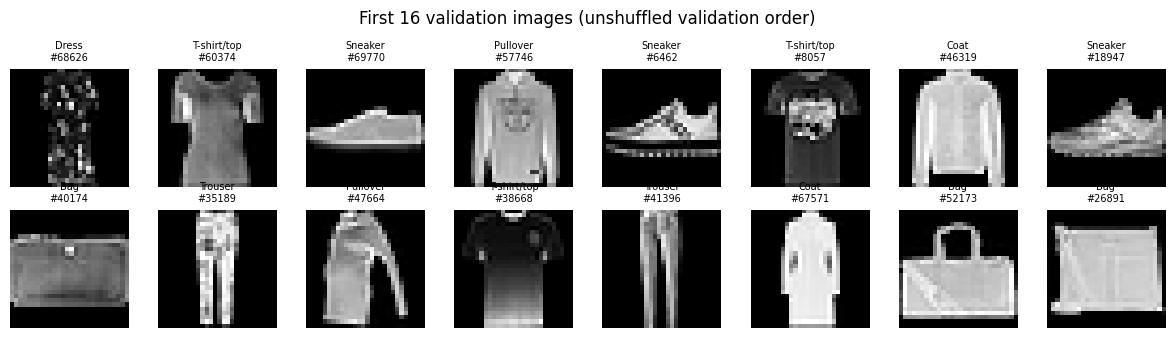

Train loader generator untouched before training: OK


In [7]:
class PooledSubset(Dataset):
    def __init__(self, indices):
        self.indices = np.asarray(indices, dtype=np.int64)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        pooled_index = int(self.indices[i])
        return images_01[pooled_index], int(labels[pooled_index]), pooled_index


loader_generator = torch.Generator(device='cpu')
loader_generator.manual_seed(LOADER_SEED)
initial_loader_state = loader_generator.get_state().clone()

train_dataset, val_dataset, test_dataset = PooledSubset(train_idx), PooledSubset(val_idx), PooledSubset(test_idx)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=loader_generator,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False)
print(f'Batches per epoch: train {len(train_loader)}, val {len(val_loader)}, test {len(test_loader)}')

val_images, val_labels, val_pooled = next(iter(val_loader))
assert val_images.shape == (BATCH_SIZE, *IMAGE_SHAPE)
assert torch.equal(val_pooled, torch.as_tensor(val_idx[:BATCH_SIZE]))
assert float(val_images.min()) >= 0.0 and float(val_images.max()) <= 1.0
dcgan_range = val_images * 2 - 1
print(f'Canonical range [{val_images.min():.3f}, {val_images.max():.3f}] -> DCGAN range [{dcgan_range.min():.3f}, {dcgan_range.max():.3f}]')

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, img, lab, pid in zip(axes.flat, val_images[:16], val_labels[:16], val_pooled[:16]):
    ax.imshow(img[0].numpy(), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{CLASS_NAMES[int(lab)]}\n#{int(pid)}', fontsize=7)
    ax.axis('off')
fig.suptitle('First 16 validation images (unshuffled validation order)')
plt.tight_layout()
plt.show()

assert torch.equal(loader_generator.get_state(), initial_loader_state), 'train loader RNG was consumed before training'
print('Train loader generator untouched before training: OK')

In [8]:
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 128, kernel_size=7, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z):
        assert z.dim() == 4 and z.shape[1:] == (LATENT_DIM, 1, 1), f'expected [B,100,1,1], got {tuple(z.shape)}'
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0, bias=True),
        )

    def forward(self, x):
        assert x.dim() == 4 and x.shape[1:] == IMAGE_SHAPE, f'expected [B,1,28,28], got {tuple(x.shape)}'
        return self.net(x).view(-1)


def weights_init(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def check_architecture(generator_model, discriminator_model):
    g_mode, d_mode = generator_model.training, discriminator_model.training
    generator_model.eval()
    discriminator_model.eval()
    dev = next(generator_model.parameters()).device
    z = torch.randn(8, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(0)).to(dev)
    g_shapes, h = [], z
    for layer in generator_model.net:
        h = layer(h)
        if isinstance(layer, nn.ConvTranspose2d):
            g_shapes.append(tuple(h.shape[1:]))
    g_out = h
    d_shapes, h = [], g_out.clone()
    for layer in discriminator_model.net:
        h = layer(h)
        if isinstance(layer, nn.Conv2d):
            d_shapes.append(tuple(h.shape[1:]))
    d_out = discriminator_model(g_out.clone())
    real = images_01[torch.as_tensor(val_idx[:8])].to(dev) * 2 - 1
    d_real = discriminator_model(real)
    generator_model.train(g_mode)
    discriminator_model.train(d_mode)
    return {
        'g_layer_shapes_ok': g_shapes == [(128, 7, 7), (64, 14, 14), (1, 28, 28)],
        'g_output_shape_ok': tuple(g_out.shape) == (8, 1, 28, 28),
        'g_output_range_ok': bool(g_out.min() >= -1.0 and g_out.max() <= 1.0),
        'g_display_range_ok': bool(((g_out + 1) / 2).min() >= 0.0 and ((g_out + 1) / 2).max() <= 1.0),
        'd_layer_shapes_ok': d_shapes == [(64, 14, 14), (128, 7, 7), (1, 1, 1)],
        'd_output_shape_ok': tuple(d_out.shape) == (8,) and tuple(d_real.shape) == (8,),
        'd_output_finite_ok': bool(torch.isfinite(d_out).all() and torch.isfinite(d_real).all()),
        'g_params_ok': count_parameters(generator_model) == EXPECTED_G_PARAMS,
        'd_params_ok': count_parameters(discriminator_model) == EXPECTED_D_PARAMS,
        'g_layer_shapes': g_shapes, 'd_layer_shapes': d_shapes,
    }


torch.manual_seed(SEED)
G = Generator().to(DEVICE)
D = Discriminator().to(DEVICE)
G.apply(weights_init)
D.apply(weights_init)

G_PARAMS, D_PARAMS = count_parameters(G), count_parameters(D)
print(G)
print(D)
print(f'Generator parameters: {G_PARAMS:,} | Discriminator parameters: {D_PARAMS:,}')
assert G_PARAMS == EXPECTED_G_PARAMS, G_PARAMS
assert D_PARAMS == EXPECTED_D_PARAMS, D_PARAMS
assert not any(isinstance(m, nn.Sigmoid) for m in D.modules())

arch_check = check_architecture(G, D)
print(arch_check)
assert all(v for k, v in arch_check.items() if k.endswith('_ok')), arch_check

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): Tanh()
  )
)
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True

In [9]:
FID_BLOCK_INDEX = InceptionV3.BLOCK_INDEX_BY_DIM[FID_FEATURE_DIM]
inception = InceptionV3([FID_BLOCK_INDEX], resize_input=True, normalize_input=True,
                        use_fid_inception=True).to(DEVICE).eval()
for p in inception.parameters():
    p.requires_grad_(False)


@torch.no_grad()
def inception_features(images01):
    assert images01.dim() == 4 and images01.shape[1:] == IMAGE_SHAPE
    assert float(images01.min()) >= 0.0 and float(images01.max()) <= 1.0
    feats = []
    for start in range(0, len(images01), FID_BATCH_SIZE):
        batch = images01[start:start + FID_BATCH_SIZE].to(DEVICE, dtype=torch.float32).repeat(1, 3, 1, 1)
        out = inception(batch)[0]
        assert out.shape[1:] == (FID_FEATURE_DIM, 1, 1), out.shape
        feats.append(out.squeeze(-1).squeeze(-1).cpu().to(torch.float64))
    feats = torch.cat(feats).numpy()
    assert feats.shape == (len(images01), FID_FEATURE_DIM) and feats.dtype == np.float64
    assert np.isfinite(feats).all()
    return feats


def feature_statistics(feats):
    feats = np.asarray(feats, dtype=np.float64)
    return feats.mean(axis=0), np.cov(feats, rowvar=False)


def compute_fid(stats_real, stats_fake):
    mu1, sigma1 = stats_real
    mu2, sigma2 = stats_fake
    value = float(calculate_frechet_distance(mu1, sigma1, mu2, sigma2))
    if not math.isfinite(value):
        raise ValueError(f'Non-finite FID: {value}')
    if value < 0:
        if value < -FID_NEGATIVE_TOLERANCE:
            raise ValueError(f'Materially negative FID: {value}')
        value = 0.0
    return value


@torch.no_grad()
def generate_images_01(generator_model, z_all):
    was_training = generator_model.training
    generator_model.eval()
    outs = []
    for start in range(0, len(z_all), GEN_BATCH_SIZE):
        out = generator_model(z_all[start:start + GEN_BATCH_SIZE].to(DEVICE))
        outs.append(((out + 1) / 2).clamp_(0.0, 1.0).float().cpu())
    generator_model.train(was_training)
    return torch.cat(outs)


val_fid_real_indices = val_idx[:VAL_FID_NUM_REAL]
val_real_images = images_01[torch.as_tensor(val_fid_real_indices)]
assert val_real_images.shape == (VAL_FID_NUM_REAL, *IMAGE_SHAPE)
t0 = time.perf_counter()
val_real_features = inception_features(val_real_images)
VAL_REAL_STATS = feature_statistics(val_real_features)
assert val_real_features.shape == (VAL_FID_NUM_REAL, FID_FEATURE_DIM)
assert VAL_REAL_STATS[1].shape == (FID_FEATURE_DIM, FID_FEATURE_DIM)
print(f'Validation real features {val_real_features.shape} in {time.perf_counter() - t0:.1f}s')

val_fid_noise = torch.randn(VAL_FID_NUM_FAKE, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(VAL_FID_NOISE_SEED))
fixed_noise = torch.randn(NUM_FIXED_NOISE, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(FIXED_NOISE_SEED))

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:01<00:00, 77.4MB/s]


Validation real features (3000, 2048) in 11.1s


In [10]:
HISTORY_FIELDS = ['epoch', 'g_loss', 'd_loss', 'd_loss_real', 'd_loss_fake', 'd_real_prob', 'd_fake_prob',
                  'fixed_pixel_std', 'fixed_pairwise_l1', 'val_fid', 'train_time_s', 'epoch_wall_time_s',
                  'num_samples', 'num_batches']


def cuda_sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()


def atomic_torch_save(obj, path):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load_checkpoint(path):
    try:
        return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        return torch.load(path, map_location='cpu')


def cpu_state_dict(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def write_history_csv(history_rows, path):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    with open(tmp, 'w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=HISTORY_FIELDS)
        writer.writeheader()
        for row in history_rows:
            writer.writerow({k: ('' if row[k] is None else row[k]) for k in HISTORY_FIELDS})
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def diversity_metrics(images01):
    flat = images01.reshape(len(images01), -1).to(torch.float64)
    pixel_std = flat.std(dim=0, unbiased=False).mean().item()
    l1 = torch.cdist(flat, flat, p=1) / flat.shape[1]
    iu = torch.triu_indices(len(flat), len(flat), offset=1)
    return pixel_std, l1[iu[0], iu[1]].mean().item()


def capture_rng_states():
    return {
        'python': random.getstate(),
        'numpy': np.random.get_state(),
        'torch_cpu': torch.get_rng_state(),
        'torch_cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }


def restore_rng_states(states):
    random.setstate(states['python'])
    np.random.set_state(states['numpy'])
    torch.set_rng_state(states['torch_cpu'])
    if states.get('torch_cuda') is not None and torch.cuda.is_available():
        if len(states['torch_cuda']) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(states['torch_cuda'])
        else:
            print('WARNING: CUDA device count changed; CUDA RNG state not restored.')


PARAMETER_COUNTS = {'generator': G_PARAMS, 'discriminator': D_PARAMS}


def make_best_checkpoint(epoch, val_fid):
    return {
        'checkpoint_type': 'best', 'model_name': 'DCGAN', 'epoch': epoch, 'val_fid': val_fid,
        'generator_state_dict': cpu_state_dict(G), 'discriminator_state_dict': cpu_state_dict(D),
        'architecture': ARCHITECTURE, 'config': CONFIG, 'parameter_counts': PARAMETER_COUNTS,
        'latent_dim': LATENT_DIM,
    }


criterion = nn.BCEWithLogitsLoss()
opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=BETAS, eps=ADAM_EPS, weight_decay=WEIGHT_DECAY)
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=BETAS, eps=ADAM_EPS, weight_decay=WEIGHT_DECAY)
train_noise_generator = torch.Generator(device='cpu')
train_noise_generator.manual_seed(TRAIN_NOISE_SEED)

history = []
best_epoch, best_val_fid, best_checkpoint = None, None, None
progression_snapshots = {}
start_epoch = 1

if RESUME:
    last = load_checkpoint(LAST_CHECKPOINT_PATH)
    if last['config'] != CONFIG:
        raise RuntimeError('Checkpoint config differs from the current notebook config; refusing to resume.')
    G.load_state_dict(last['generator_state_dict'])
    D.load_state_dict(last['discriminator_state_dict'])
    opt_G.load_state_dict(last['optimizer_G_state_dict'])
    opt_D.load_state_dict(last['optimizer_D_state_dict'])
    history = list(last['history'])
    best_epoch, best_val_fid = last['best_epoch'], last['best_val_fid']
    best_checkpoint = last['best_checkpoint']
    progression_snapshots = {int(k): v.clone() for k, v in last['progression_snapshots'].items()}
    train_noise_generator.set_state(last['train_noise_generator_state'])
    loader_generator.set_state(last['loader_generator_state'])
    restore_rng_states(last['rng_states'])
    start_epoch = int(last['epoch']) + 1
    assert [r['epoch'] for r in history] == list(range(1, start_epoch))
    if best_checkpoint is not None:
        atomic_torch_save(best_checkpoint, BEST_MODEL_PATH)
    write_history_csv(history, HISTORY_CSV_PATH)
    del last
    print(f'Resumed after epoch {start_epoch - 1}; best epoch so far: {best_epoch} (val FID {best_val_fid})')

for epoch in range(start_epoch, NUM_EPOCHS + 1):
    cuda_sync()
    epoch_start = time.perf_counter()
    G.train()
    D.train()
    sums = torch.zeros(6, dtype=torch.float64, device=DEVICE)
    num_samples, num_batches = 0, 0

    cuda_sync()
    train_start = time.perf_counter()
    for real01, _, _ in tqdm(train_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS}', leave=False):
        real = real01.to(DEVICE, non_blocking=True) * 2 - 1
        b = real.size(0)
        ones = torch.ones(b, device=DEVICE)
        zeros = torch.zeros(b, device=DEVICE)

        z_d = torch.randn(b, LATENT_DIM, 1, 1, generator=train_noise_generator).to(DEVICE, non_blocking=True)
        with torch.no_grad():
            fake_d = G(z_d)
        opt_D.zero_grad(set_to_none=True)
        logits_real = D(real)
        logits_fake = D(fake_d.detach())
        loss_d_real = criterion(logits_real, ones)
        loss_d_fake = criterion(logits_fake, zeros)
        loss_d = 0.5 * (loss_d_real + loss_d_fake)
        loss_d.backward()
        opt_D.step()

        for p in D.parameters():
            p.requires_grad_(False)
        try:
            z_g = torch.randn(b, LATENT_DIM, 1, 1, generator=train_noise_generator).to(DEVICE, non_blocking=True)
            opt_G.zero_grad(set_to_none=True)
            loss_g = criterion(D(G(z_g)), ones)
            loss_g.backward()
            opt_G.step()
        finally:
            for p in D.parameters():
                p.requires_grad_(True)

        with torch.no_grad():
            sums += torch.stack([
                loss_g.detach().double() * b, loss_d.detach().double() * b,
                loss_d_real.detach().double() * b, loss_d_fake.detach().double() * b,
                torch.sigmoid(logits_real.detach()).double().sum(), torch.sigmoid(logits_fake.detach()).double().sum(),
            ])
        num_samples += b
        num_batches += 1
    cuda_sync()
    train_time = time.perf_counter() - train_start
    means = (sums / num_samples).cpu().tolist()
    if not all(math.isfinite(v) for v in means):
        raise FloatingPointError(f'Non-finite training statistics at epoch {epoch}: {means}')

    fixed_images = generate_images_01(G, fixed_noise)
    pixel_std, pairwise_l1 = diversity_metrics(fixed_images)
    if epoch in PROGRESSION_EPOCHS:
        progression_snapshots[epoch] = fixed_images[:PROGRESSION_IMAGES].clone()

    val_fid = None
    if epoch in VAL_FID_EPOCHS:
        val_fake_images = generate_images_01(G, val_fid_noise)
        assert val_fake_images.shape == (VAL_FID_NUM_FAKE, *IMAGE_SHAPE)
        val_fake_features = inception_features(val_fake_images)
        assert val_fake_features.shape == (VAL_FID_NUM_FAKE, FID_FEATURE_DIM)
        val_fid = compute_fid(VAL_REAL_STATS, feature_statistics(val_fake_features))
        del val_fake_images, val_fake_features
    cuda_sync()
    epoch_wall_time = time.perf_counter() - epoch_start

    row = {
        'epoch': epoch, 'g_loss': means[0], 'd_loss': means[1], 'd_loss_real': means[2], 'd_loss_fake': means[3],
        'd_real_prob': means[4], 'd_fake_prob': means[5], 'fixed_pixel_std': pixel_std,
        'fixed_pairwise_l1': pairwise_l1, 'val_fid': val_fid, 'train_time_s': train_time,
        'epoch_wall_time_s': epoch_wall_time, 'num_samples': num_samples, 'num_batches': num_batches,
    }
    history.append(row)

    if val_fid is not None and (best_val_fid is None or val_fid < best_val_fid):
        best_epoch, best_val_fid = epoch, val_fid
        best_checkpoint = make_best_checkpoint(epoch, val_fid)
        atomic_torch_save(best_checkpoint, BEST_MODEL_PATH)

    last_checkpoint = {
        'checkpoint_type': 'last', 'model_name': 'DCGAN', 'epoch': epoch,
        'generator_state_dict': cpu_state_dict(G), 'discriminator_state_dict': cpu_state_dict(D),
        'optimizer_G_state_dict': opt_G.state_dict(), 'optimizer_D_state_dict': opt_D.state_dict(),
        'history': history, 'best_epoch': best_epoch, 'best_val_fid': best_val_fid,
        'best_checkpoint': best_checkpoint,
        'rng_states': capture_rng_states(),
        'train_noise_generator_state': train_noise_generator.get_state(),
        'loader_generator_state': loader_generator.get_state(),
        'progression_snapshots': progression_snapshots,
        'architecture': ARCHITECTURE, 'config': CONFIG, 'parameter_counts': PARAMETER_COUNTS,
        'latent_dim': LATENT_DIM,
    }
    atomic_torch_save(last_checkpoint, LAST_CHECKPOINT_PATH)
    del last_checkpoint
    write_history_csv(history, HISTORY_CSV_PATH)

    fid_text = f' | val FID {val_fid:.3f}' if val_fid is not None else ''
    print(f'Epoch {epoch:2d} | G {means[0]:.4f} | D {means[1]:.4f} | D(real) {means[4]:.3f} | D(fake) {means[5]:.3f} '
          f'| pix-std {pixel_std:.4f} | pair-L1 {pairwise_l1:.4f}{fid_text} | train {train_time:.1f}s | wall {epoch_wall_time:.1f}s')

assert len(history) == NUM_EPOCHS and [r['epoch'] for r in history] == list(range(1, NUM_EPOCHS + 1))
assert sorted(progression_snapshots) == PROGRESSION_EPOCHS
print(f'Training complete. Best epoch {best_epoch} with validation FID {best_val_fid:.4f}')

Epoch 1/30:   0%|          | 0/438 [00:00<?, ?it/s]

Epoch  1 | G 2.1273 | D 0.2181 | D(real) 0.828 | D(fake) 0.186 | pix-std 0.2321 | pair-L1 0.2492 | train 11.7s | wall 11.7s


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ed267662160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    Exception ignored in: self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
<function _MultiProcessingDataLoaderIter.__del__ at 0x7ed267662160>    
if w.is_alive():Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    

Epoch 2/30:   0%|          | 0/438 [00:00<?, ?it/s]

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    self._shutdown_workers()assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
AssertionError    : can only test a child processif w.is_alive():

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ed267662160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1638, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive


Epoch  2 | G 2.0896 | D 0.2503 | D(real) 0.806 | D(fake) 0.191 | pix-std 0.2542 | pair-L1 0.2650 | train 11.7s | wall 11.7s


... (62 outputs left out)

Epoch 29/30:   0%|          | 0/438 [00:00<?, ?it/s]

Epoch 29 | G 1.1997 | D 0.5303 | D(real) 0.630 | D(fake) 0.369 | pix-std 0.2603 | pair-L1 0.2680 | train 12.3s | wall 12.3s


Epoch 30/30:   0%|          | 0/438 [00:00<?, ?it/s]

Epoch 30 | G 1.2070 | D 0.5271 | D(real) 0.631 | D(fake) 0.369 | pix-std 0.2651 | pair-L1 0.2731 | val FID 27.572 | train 12.0s | wall 40.3s
Training complete. Best epoch 30 with validation FID 27.5716


Loaded best checkpoint: epoch 30, validation FID 27.5716


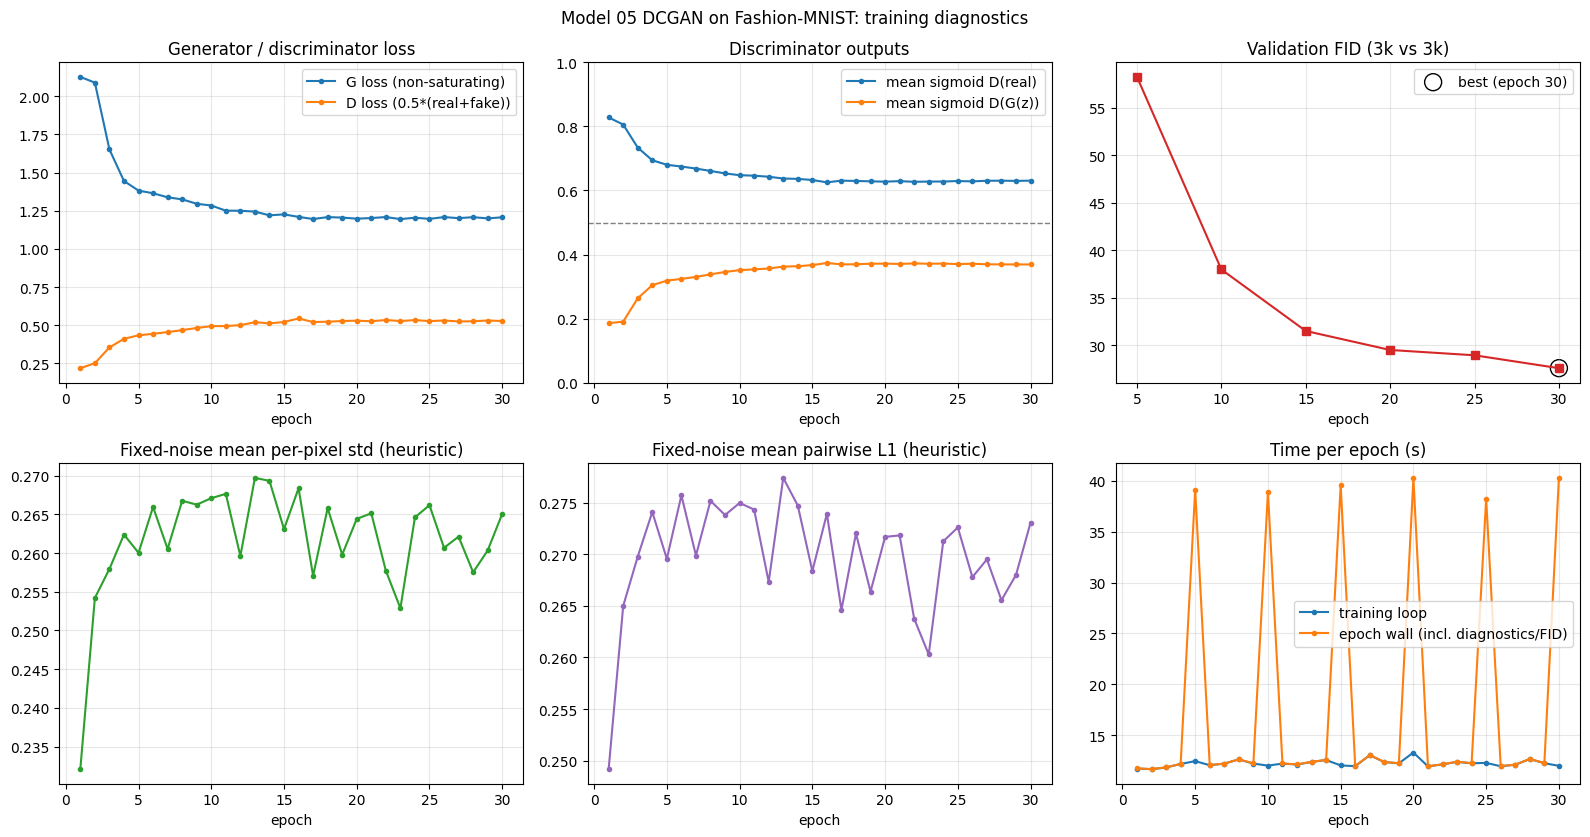

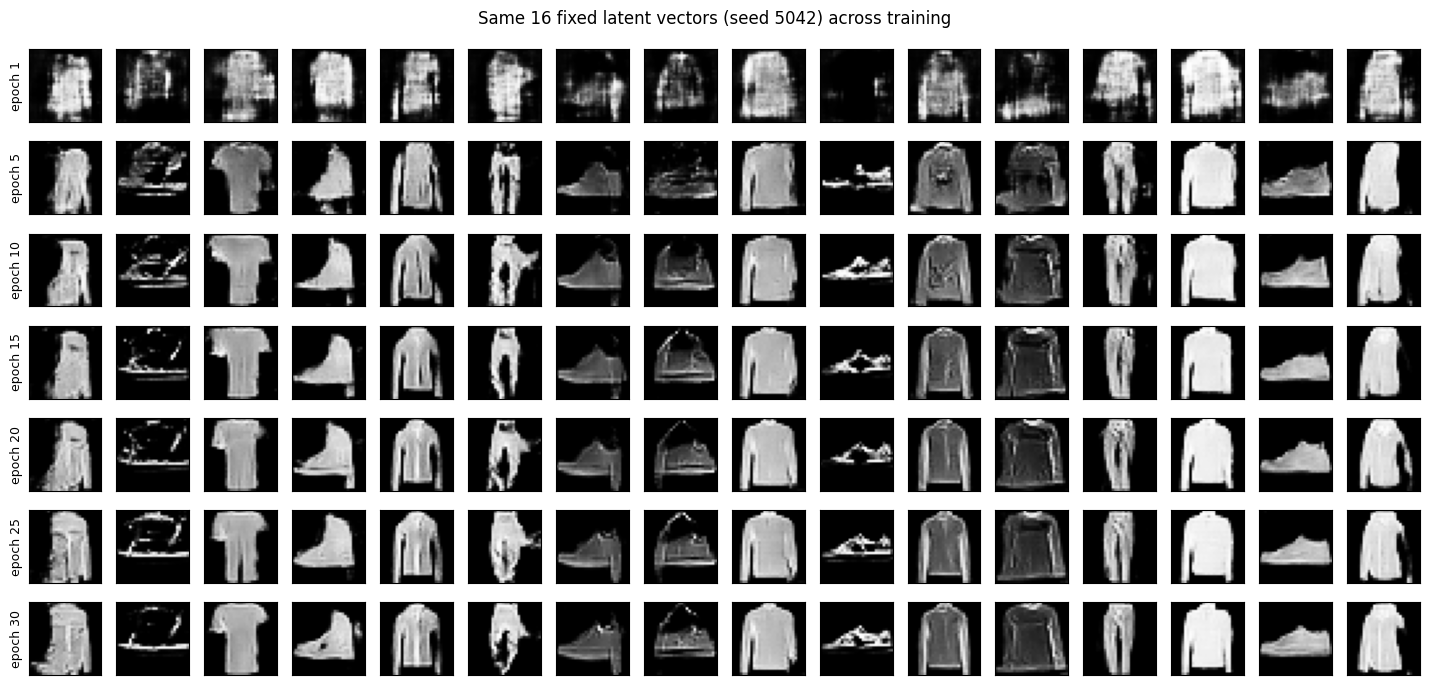

In [11]:
best_ckpt = load_checkpoint(BEST_MODEL_PATH)
G_best = Generator().to(DEVICE)
D_best = Discriminator().to(DEVICE)
G_best.load_state_dict(best_ckpt['generator_state_dict'])
D_best.load_state_dict(best_ckpt['discriminator_state_dict'])
G_best.eval()
D_best.eval()

scheduled_fids = {r['epoch']: r['val_fid'] for r in history if r['val_fid'] is not None}
assert sorted(scheduled_fids) == VAL_FID_EPOCHS
argmin_epoch = min(scheduled_fids, key=lambda e: (scheduled_fids[e], e))
assert best_ckpt['epoch'] == best_epoch == argmin_epoch
assert abs(best_ckpt['val_fid'] - scheduled_fids[argmin_epoch]) < 1e-12
print(f'Loaded best checkpoint: epoch {best_ckpt["epoch"]}, validation FID {best_ckpt["val_fid"]:.4f}')

epochs = [r['epoch'] for r in history]


def col(key):
    return [r[key] for r in history]


fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
ax = axes[0, 0]
ax.plot(epochs, col('g_loss'), marker='o', ms=3, label='G loss (non-saturating)')
ax.plot(epochs, col('d_loss'), marker='o', ms=3, label='D loss (0.5*(real+fake))')
ax.set_title('Generator / discriminator loss'); ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=0.3)
ax = axes[0, 1]
ax.plot(epochs, col('d_real_prob'), marker='o', ms=3, label='mean sigmoid D(real)')
ax.plot(epochs, col('d_fake_prob'), marker='o', ms=3, label='mean sigmoid D(G(z))')
ax.axhline(0.5, color='gray', ls='--', lw=1)
ax.set_ylim(0, 1); ax.set_title('Discriminator outputs'); ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=0.3)
ax = axes[0, 2]
fid_epochs = sorted(scheduled_fids)
ax.plot(fid_epochs, [scheduled_fids[e] for e in fid_epochs], marker='s', color='tab:red')
ax.scatter([best_epoch], [best_val_fid], s=150, facecolors='none', edgecolors='k', label=f'best (epoch {best_epoch})')
ax.set_xticks(VAL_FID_EPOCHS); ax.set_title('Validation FID (3k vs 3k)'); ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=0.3)
ax = axes[1, 0]
ax.plot(epochs, col('fixed_pixel_std'), marker='o', ms=3, color='tab:green')
ax.set_title('Fixed-noise mean per-pixel std (heuristic)'); ax.set_xlabel('epoch'); ax.grid(alpha=0.3)
ax = axes[1, 1]
ax.plot(epochs, col('fixed_pairwise_l1'), marker='o', ms=3, color='tab:purple')
ax.set_title('Fixed-noise mean pairwise L1 (heuristic)'); ax.set_xlabel('epoch'); ax.grid(alpha=0.3)
ax = axes[1, 2]
ax.plot(epochs, col('train_time_s'), marker='o', ms=3, label='training loop')
ax.plot(epochs, col('epoch_wall_time_s'), marker='o', ms=3, label='epoch wall (incl. diagnostics/FID)')
ax.set_title('Time per epoch (s)'); ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=0.3)
fig.suptitle('Model 05 DCGAN on Fashion-MNIST: training diagnostics')
plt.tight_layout()
fig.savefig(FIG_TRAINING_CURVES, dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(len(PROGRESSION_EPOCHS), PROGRESSION_IMAGES,
                         figsize=(PROGRESSION_IMAGES * 0.9, len(PROGRESSION_EPOCHS) * 1.0))
for row_i, ep in enumerate(PROGRESSION_EPOCHS):
    snap = progression_snapshots[ep]
    assert snap.shape == (PROGRESSION_IMAGES, *IMAGE_SHAPE)
    for col_i in range(PROGRESSION_IMAGES):
        ax = axes[row_i, col_i]
        ax.imshow(snap[col_i, 0].numpy(), cmap='gray', vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if col_i == 0:
            ax.set_ylabel(f'epoch {ep}', fontsize=9)
fig.suptitle('Same 16 fixed latent vectors (seed 5042) across training')
plt.tight_layout()
fig.savefig(FIG_PROGRESSION, dpi=150, bbox_inches='tight')
plt.show()

In [12]:
test_real_images = images_01[torch.as_tensor(test_idx)]
assert np.intersect1d(test_idx, train_idx).size == 0
assert test_real_images.shape == (TEST_FID_NUM_REAL, *IMAGE_SHAPE)

test_noise = torch.randn(TEST_FID_NUM_FAKE, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(TEST_FID_NOISE_SEED))
test_fake_images = generate_images_01(G_best, test_noise)
assert test_fake_images.shape == (TEST_FID_NUM_FAKE, *IMAGE_SHAPE)

t0 = time.perf_counter()
test_real_features = inception_features(test_real_images)
test_fake_features = inception_features(test_fake_images)
test_fid_time = time.perf_counter() - t0
assert test_real_features.shape == (TEST_FID_NUM_REAL, FID_FEATURE_DIM)
assert test_fake_features.shape == (TEST_FID_NUM_FAKE, FID_FEATURE_DIM)

TEST_FID = compute_fid(feature_statistics(test_real_features), feature_statistics(test_fake_features))
TEST_FID_RECORD = {
    'value': TEST_FID,
    'num_real': int(test_real_features.shape[0]),
    'num_generated': int(test_fake_features.shape[0]),
    'real_feature_shape': list(test_real_features.shape),
    'generated_feature_shape': list(test_fake_features.shape),
    'feature_dim': int(test_real_features.shape[1]),
    'real_source': 'test split (all 7,000 images)',
    'generated_source': f'best generator (epoch {best_epoch}), fresh z ~ N(0,I), seed {TEST_FID_NOISE_SEED}',
    'checkpoint_epoch': best_epoch,
    'compute_time_s': test_fid_time,
}
print(f'Final held-out test FID (7,000 real test vs 7,000 generated): {TEST_FID:.4f}')
del test_real_images, test_fake_images

Final held-out test FID (7,000 real test vs 7,000 generated): 22.9571


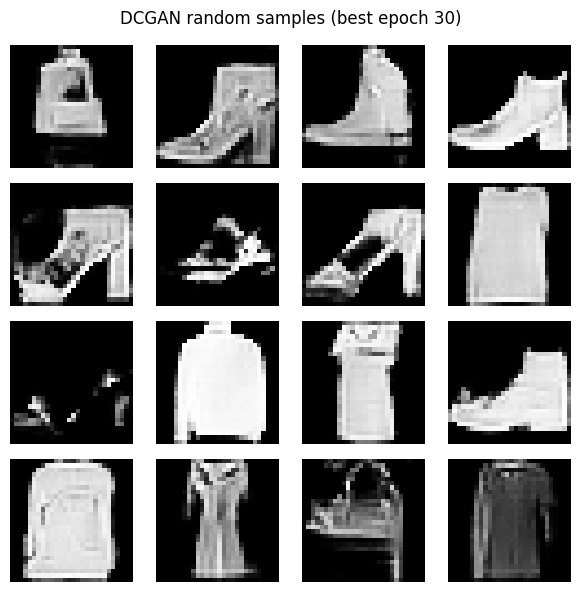

In [13]:
grid_noise = torch.randn(16, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(RANDOM_GRID_SEED))
grid_images = generate_images_01(G_best, grid_noise)
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, img in zip(axes.flat, grid_images):
    ax.imshow(img[0].numpy(), cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
fig.suptitle(f'DCGAN random samples (best epoch {best_epoch})')
plt.tight_layout()
fig.savefig(FIG_RANDOM_SAMPLES, dpi=150, bbox_inches='tight')
plt.show()

 T-shirt/top | pooled #39323 (test pos 0) | restart 3 | MSE 0.00494 | objective 0.00513 | |z| 13.785
     Trouser | pooled #6906 (test pos 3) | restart 1 | MSE 0.00236 | objective 0.00243 | |z| 8.699


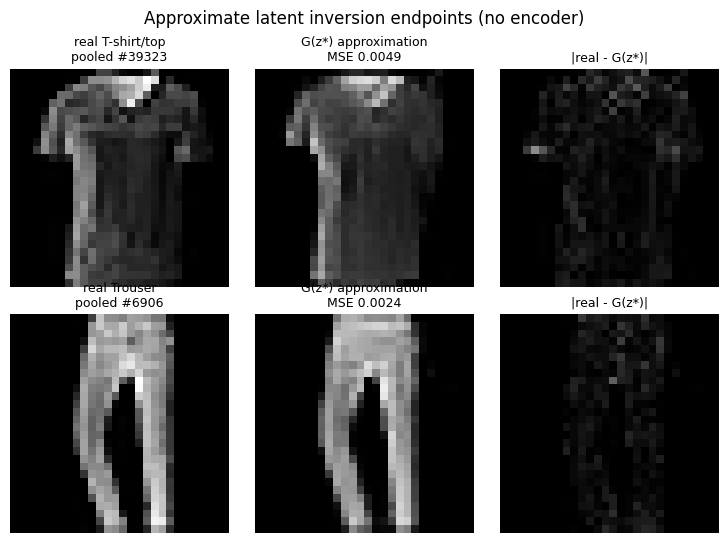

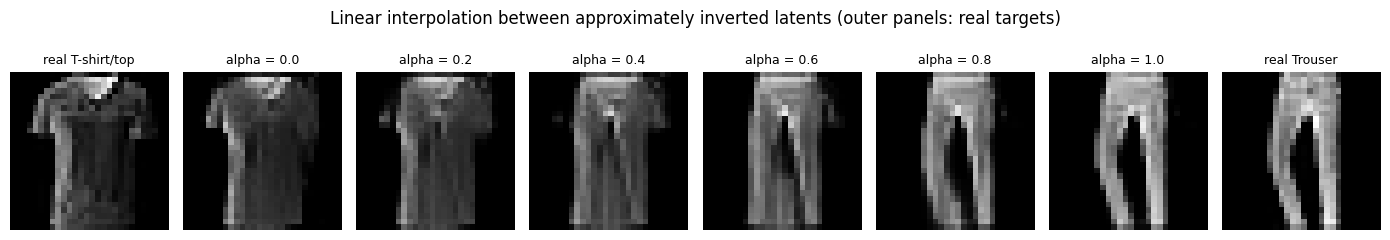

In [14]:
for p in G_best.parameters():
    p.requires_grad_(False)
G_best.eval()


def invert_image(target01, endpoint_number):
    target = target01.unsqueeze(0).to(DEVICE)
    restarts = []
    best = None
    for restart in range(INV_RESTARTS):
        seed = INVERSION_SEED + 100 * endpoint_number + restart
        z = torch.randn(1, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(seed)).to(DEVICE)
        z.requires_grad_(True)
        optimizer = torch.optim.Adam([z], lr=INV_LR)
        for _ in range(INV_STEPS):
            optimizer.zero_grad(set_to_none=True)
            recon = (G_best(z) + 1) / 2
            objective = F.mse_loss(recon, target) + INV_LATENT_REG * z.pow(2).mean()
            objective.backward()
            optimizer.step()
        with torch.no_grad():
            recon = (G_best(z) + 1) / 2
            mse = F.mse_loss(recon, target).item()
            objective = mse + INV_LATENT_REG * z.pow(2).mean().item()
        record = {'restart': restart, 'seed': seed, 'final_objective': objective, 'final_mse': mse,
                  'latent_l2_norm': z.detach().norm().item()}
        restarts.append(record)
        if best is None or objective < best[0]['final_objective']:
            best = (record, z.detach().clone(), recon.detach().clamp(0, 1).cpu()[0])
    return best, restarts


inversion_results = []
for endpoint_number, class_id in enumerate(INTERP_CLASSES):
    test_position = int(np.flatnonzero(labels[test_idx] == class_id)[0])
    pooled_index = int(test_idx[test_position])
    source_split, source_index = pooled_source(pooled_index)
    target = images_01[pooled_index]
    (best_record, z_opt, recon), restarts = invert_image(target, endpoint_number)
    inversion_results.append({
        'endpoint': 'A' if endpoint_number == 0 else 'B', 'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
        'test_split_position': test_position, 'pooled_index': pooled_index,
        'source_dataset': f'Fashion-MNIST official {source_split}', 'source_index': source_index,
        'selected_restart': best_record['restart'], 'final_mse': best_record['final_mse'],
        'final_objective': best_record['final_objective'], 'latent_l2_norm': best_record['latent_l2_norm'],
        'restarts': restarts, 'z': z_opt.cpu(), 'target': target, 'recon': recon,
    })
    print(f'{CLASS_NAMES[class_id]:>12} | pooled #{pooled_index} (test pos {test_position}) | restart {best_record["restart"]} '
          f'| MSE {best_record["final_mse"]:.5f} | objective {best_record["final_objective"]:.5f} | |z| {best_record["latent_l2_norm"]:.3f}')

fig, axes = plt.subplots(2, 3, figsize=(7.5, 5.5))
for row_i, res in enumerate(inversion_results):
    diff = (res['target'] - res['recon']).abs()
    for col_i, (img, title) in enumerate([
            (res['target'], f'real {res["class_name"]}\npooled #{res["pooled_index"]}'),
            (res['recon'], f'G(z*) approximation\nMSE {res["final_mse"]:.4f}'),
            (diff, '|real - G(z*)|')]):
        axes[row_i, col_i].imshow(img[0].numpy(), cmap='gray', vmin=0, vmax=1)
        axes[row_i, col_i].set_title(title, fontsize=9)
        axes[row_i, col_i].axis('off')
fig.suptitle('Approximate latent inversion endpoints (no encoder)')
plt.tight_layout()
fig.savefig(FIG_INVERSION, dpi=150, bbox_inches='tight')
plt.show()

z_a, z_b = inversion_results[0]['z'], inversion_results[1]['z']
interp_z = torch.cat([(1 - a) * z_a + a * z_b for a in INTERP_ALPHAS])
assert interp_z.shape == (len(INTERP_ALPHAS), LATENT_DIM, 1, 1)
interp_images = generate_images_01(G_best, interp_z)

fig, axes = plt.subplots(1, len(INTERP_ALPHAS) + 2, figsize=(14, 2.6))
axes[0].imshow(inversion_results[0]['target'][0].numpy(), cmap='gray', vmin=0, vmax=1)
axes[0].set_title(f'real {CLASS_NAMES[INTERP_CLASSES[0]]}', fontsize=9)
for i, (a, img) in enumerate(zip(INTERP_ALPHAS, interp_images), start=1):
    axes[i].imshow(img[0].numpy(), cmap='gray', vmin=0, vmax=1)
    axes[i].set_title(f'alpha = {a:.1f}', fontsize=9)
axes[-1].imshow(inversion_results[1]['target'][0].numpy(), cmap='gray', vmin=0, vmax=1)
axes[-1].set_title(f'real {CLASS_NAMES[INTERP_CLASSES[1]]}', fontsize=9)
for ax in axes:
    ax.axis('off')
fig.suptitle('Linear interpolation between approximately inverted latents (outer panels: real targets)')
plt.tight_layout()
fig.savefig(FIG_INTERPOLATION, dpi=150, bbox_inches='tight')
plt.show()

INTERPOLATION_RECORD = {
    'method': 'approximate latent inversion (not a learned encoder) + linear interpolation in z',
    'alphas': INTERP_ALPHAS,
    'num_steps': len(INTERP_ALPHAS),
    'inversion_objective': 'MSE((G(z)+1)/2, target) + 1e-4 * mean(z^2)',
    'restarts_per_endpoint': INV_RESTARTS, 'steps_per_restart': INV_STEPS, 'optimizer': 'Adam', 'lr': INV_LR,
    'latent_reg': INV_LATENT_REG, 'generator_checkpoint_epoch': best_epoch,
    'endpoints': [{k: v for k, v in r.items() if k not in ('z', 'target', 'recon')} for r in inversion_results],
    'interpolated_latent_l2_norms': [float(v) for v in interp_z.flatten(1).norm(dim=1)],
}

In [15]:
latency_z = torch.randn(LATENCY_BATCH, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(LATENCY_SEED)).to(DEVICE)
G_best.eval()
timings_ms = []
with torch.no_grad():
    for _ in range(LATENCY_WARMUP):
        _ = G_best(latency_z)
    cuda_sync()
    for _ in range(LATENCY_RUNS):
        cuda_sync()
        t0 = time.perf_counter()
        _ = G_best(latency_z)
        cuda_sync()
        timings_ms.append((time.perf_counter() - t0) * 1000.0)
timings_ms = np.asarray(timings_ms, dtype=np.float64)
assert len(timings_ms) == LATENCY_RUNS

LATENCY_RECORD = {
    'batch_size': LATENCY_BATCH, 'warmup_runs': LATENCY_WARMUP, 'timed_runs': int(len(timings_ms)),
    'mean_ms_per_batch': float(timings_ms.mean()), 'std_ms_per_batch': float(timings_ms.std(ddof=1)),
    'median_ms_per_batch': float(np.median(timings_ms)), 'min_ms_per_batch': float(timings_ms.min()),
    'max_ms_per_batch': float(timings_ms.max()), 'mean_ms_per_image': float(timings_ms.mean() / LATENCY_BATCH),
    'device': str(DEVICE), 'gpu_name': GPU_NAME, 'torch_version': torch.__version__,
    'scope': 'Generator forward pass only; no FID, no postprocessing, no host transfer',
    'note': 'Hardware dependent: compare only across runs on the same GPU/runtime.',
}
print(json.dumps(LATENCY_RECORD, indent=2))

{
  "batch_size": 64,
  "warmup_runs": 20,
  "timed_runs": 100,
  "mean_ms_per_batch": 3.4272882999880494,
  "std_ms_per_batch": 1.0886834346753442,
  "median_ms_per_batch": 3.0411359999789056,
  "min_ms_per_batch": 2.9402679999748216,
  "max_ms_per_batch": 6.593059000124413,
  "mean_ms_per_image": 0.05355137968731327,
  "device": "cuda",
  "gpu_name": "Tesla T4",
  "torch_version": "2.14.1+cu130",
  "scope": "Generator forward pass only; no FID, no postprocessing, no host transfer",
  "note": "Hardware dependent: compare only across runs on the same GPU/runtime."
}


In [16]:
def summary(values):
    arr = np.asarray(values, dtype=np.float64)
    return {'first': float(arr[0]), 'last': float(arr[-1]), 'min': float(arr.min()), 'max': float(arr.max()),
            'mean': float(arr.mean()), 'std': float(arr.std())}


best_row = history[best_epoch - 1]
metrics = {
    'model_id': '05', 'model_name': 'DCGAN', 'model_type': 'unconditional convolutional GAN',
    'notebook': '05_dcgan_claude.ipynb', 'dataset': 'Fashion-MNIST',
    'architecture': ARCHITECTURE,
    'parameter_counts': {'generator': G_PARAMS, 'discriminator': D_PARAMS, 'total': G_PARAMS + D_PARAMS},
    'latent_dim': LATENT_DIM,
    'hyperparameters': {**CONFIG['training'], 'seeds': CONFIG['seeds'], 'dataloader': CONFIG['dataloader'],
                        'latent_inversion': CONFIG['latent_inversion']},
    'split': {
        'totals': split_report['totals'], 'per_class_counts': split_report['per_class_counts'],
        'sha256_int64_index_bytes': SPLIT_HASHES, 'seed': SPLIT_SEED,
    },
    'model_selection': {
        'criterion': 'lowest validation FID at scheduled epochs',
        'best_epoch': best_epoch, 'best_val_fid': best_val_fid,
        'val_fid_by_epoch': {str(e): scheduled_fids[e] for e in VAL_FID_EPOCHS},
        'note': 'Validation FID is used only for checkpoint selection; it is not the final reported metric.',
    },
    'final_test_fid': TEST_FID_RECORD,
    'fid_protocol': {**CONFIG['fid'],
        'limitations': ('FID InceptionV3 was trained on ImageNet RGB photographs; Fashion-MNIST images are 28x28 grayscale, '
                        'repeated to 3 channels and upsampled to 299x299, so features are a proxy. Finite-sample FID is biased '
                        'upward; values are comparable only across Models 01-05 under this identical protocol. '
                        'No domain-specific FID is used.'),
    },
    'reconstruction_metrics': {'mse': None, 'psnr': None, 'ssim': None, 'status': 'N/A',
                               'reason': 'Unconditional DCGAN has no encoder and does not reconstruct inputs.'},
    'training_history_summary': {
        'epochs_recorded': len(history),
        'g_loss': summary(col('g_loss')), 'd_loss': summary(col('d_loss')),
        'd_real_prob': summary(col('d_real_prob')), 'd_fake_prob': summary(col('d_fake_prob')),
        'best_epoch_row': best_row,
    },
    'timing': {
        'total_train_time_s': float(sum(col('train_time_s'))),
        'total_epoch_wall_time_s': float(sum(col('epoch_wall_time_s'))),
        'mean_train_time_per_epoch_s': float(np.mean(col('train_time_s'))),
        'mean_epoch_wall_time_s': float(np.mean(col('epoch_wall_time_s'))),
        'definitions': {'train_time_s': 'batch loop only (CUDA synchronized)',
                        'epoch_wall_time_s': 'training + fixed-noise diagnostics + scheduled validation FID; excludes checkpoint/CSV writes'},
        'resumed_run': bool(RESUME),
    },
    'diversity_diagnostics': {
        'fixed_noise_seed': FIXED_NOISE_SEED, 'num_fixed_noise': NUM_FIXED_NOISE,
        'pixel_std_by_epoch': col('fixed_pixel_std'), 'pairwise_l1_by_epoch': col('fixed_pairwise_l1'),
        'pixel_std_at_best_epoch': best_row['fixed_pixel_std'], 'pairwise_l1_at_best_epoch': best_row['fixed_pairwise_l1'],
        'definitions': CONFIG['diagnostics'],
        'caveat': ('Heuristic pixel-space diversity signals only. They cannot prove or rule out mode collapse and do not '
                   'measure mode coverage.'),
    },
    'inference_latency': LATENCY_RECORD,
    'latent_inversion_interpolation': INTERPOLATION_RECORD,
    'environment': {**VERSIONS, 'device': str(DEVICE), 'gpu_name': GPU_NAME},
    'artifacts': {str(p.relative_to(PROJECT_ROOT)): str(p) for p in REQUIRED_ARTIFACTS},
    'storage_note': 'Dataset cache and .pth checkpoints stay in Google Drive; notebook, JSON, CSV and figures may be committed.',
}

save_json(metrics, METRICS_PATH)
save_json(CONFIG, CONFIG_PATH)
save_json(split_report, SPLIT_REPORT_PATH)
write_history_csv(history, HISTORY_CSV_PATH)

for path in REQUIRED_ARTIFACTS:
    size = path.stat().st_size if path.exists() else 0
    print(f'{size:>12,d} B  {path}')

   3,610,725 B  /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/best_model.pth
  14,794,809 B  /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/checkpoints/last_checkpoint.pth
      18,062 B  /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/metrics.json
       6,428 B  /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/training_history.csv
       6,428 B  /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/experiment_config.json
       2,473 B  /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/split_report.json
     281,194 B  /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/figures/training_curves.png
      39,825 B  /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/figures/random_samples_4x4.png
     197,698 B  /content/drive/MyDrive/generative-model-comparison/05_dcgan/results/figures/training_sample_progression.png
      39,610 B  /conten

In [17]:
checks = []


def check(name, condition):
    ok = bool(condition)
    checks.append((name, ok))
    print(f'[{"PASS" if ok else "FAIL"}] {name}')


def safe(fn, default=None):
    try:
        return fn()
    except Exception as exc:
        print('   error while checking:', repr(exc))
        return default

for path in REQUIRED_ARTIFACTS:
    check(f'artifact exists and non-empty: {path.relative_to(PROJECT_ROOT)}', path.exists() and path.stat().st_size > 0)

m = safe(lambda: load_json_strict(METRICS_PATH))
cfg = safe(lambda: load_json_strict(CONFIG_PATH))
sr = safe(lambda: load_json_strict(SPLIT_REPORT_PATH))
check('metrics.json is strict JSON (no NaN/Infinity)', m is not None)
check('experiment_config.json is strict JSON (no NaN/Infinity)', cfg is not None)
check('split_report.json is strict JSON (no NaN/Infinity)', sr is not None)
m, cfg, sr = m or {}, cfg or {}, sr or {}

tr2, va2, te2 = make_shared_split(labels)
check('split regenerates identically', np.array_equal(tr2, train_idx) and np.array_equal(va2, val_idx) and np.array_equal(te2, test_idx))
check('split totals 56,000 / 7,000 / 7,000', (len(train_idx), len(val_idx), len(test_idx)) == (56000, 7000, 7000))
check('split per-class 5,600 / 700 / 700, unique, disjoint, full 70,000 coverage', not verify_split(train_idx, val_idx, test_idx))
recomputed_hashes = {'train': sha256_int64(train_idx), 'val': sha256_int64(val_idx), 'test': sha256_int64(test_idx)}
check('split hashes match split_report.json', sr.get('sha256_int64_index_bytes') == recomputed_hashes)
check('split hashes match metrics.json', m.get('split', {}).get('sha256_int64_index_bytes') == recomputed_hashes)
check('split report per-class counts', all(
    len(sr.get('per_class_counts', {}).get(s, {})) == 10 and set(sr['per_class_counts'][s].values()) == {n}
    for s, n in [('train', 5600), ('val', 700), ('test', 700)]))
for name, expected in EXPECTED_SPLIT_SHA256.items():
    if expected is not None:
        check(f'{name} hash equals provided Models 01-04 hash', recomputed_hashes[name] == expected)

ac = safe(lambda: check_architecture(G_best, D_best), {})
for key in ['g_layer_shapes_ok', 'g_output_shape_ok', 'g_output_range_ok', 'g_display_range_ok',
            'd_layer_shapes_ok', 'd_output_shape_ok', 'd_output_finite_ok', 'g_params_ok', 'd_params_ok']:
    check(f'architecture: {key}', ac.get(key, False))
check('parameter counts in metrics: G=759,680, D=138,625',
      m.get('parameter_counts', {}).get('generator') == 759680 and m.get('parameter_counts', {}).get('discriminator') == 138625)

with open(HISTORY_CSV_PATH, newline='', encoding='utf-8') as f:
    csv_rows = list(csv.DictReader(f))
check('30 epochs recorded in CSV', [int(r['epoch']) for r in csv_rows] == list(range(1, 31)))
check('30 epochs recorded in metrics', m.get('training_history_summary', {}).get('epochs_recorded') == 30)
csv_fid_epochs = [int(r['epoch']) for r in csv_rows if r['val_fid'] != '']
check('validation FID only at epochs 5,10,15,20,25,30 (CSV)', csv_fid_epochs == VAL_FID_EPOCHS)
check('validation FID only at epochs 5,10,15,20,25,30 (metrics)',
      sorted(int(e) for e in m.get('model_selection', {}).get('val_fid_by_epoch', {})) == VAL_FID_EPOCHS)
csv_fids = {int(r['epoch']): float(r['val_fid']) for r in csv_rows if r['val_fid'] != ''}
csv_best = min(csv_fids, key=lambda e: (csv_fids[e], e)) if csv_fids else None
check('best epoch is the lowest scheduled validation FID',
      csv_best is not None and m.get('model_selection', {}).get('best_epoch') == csv_best)
check('progression snapshots for epochs 1,5,10,15,20,25,30 (>=16 images each)',
      sorted(progression_snapshots) == PROGRESSION_EPOCHS and all(v.shape[0] >= 16 for v in progression_snapshots.values()))

bc = safe(lambda: load_checkpoint(BEST_MODEL_PATH), {})
lc = safe(lambda: load_checkpoint(LAST_CHECKPOINT_PATH), {})
ms = m.get('model_selection', {})
check('best checkpoint epoch / val FID match metrics', bc.get('epoch') == ms.get('best_epoch')
      and bc.get('val_fid') is not None and abs(bc['val_fid'] - ms.get('best_val_fid', float('inf'))) < 1e-9)
check('best checkpoint config / parameter counts match config file',
      bc.get('config') == cfg and bc.get('parameter_counts') == {'generator': 759680, 'discriminator': 138625})
check('best checkpoint has G and D states and architecture', all(k in bc for k in ('generator_state_dict', 'discriminator_state_dict', 'architecture')))
check('last checkpoint epoch 30 and best metadata match', lc.get('epoch') == 30 and lc.get('best_epoch') == ms.get('best_epoch')
      and lc.get('best_val_fid') == bc.get('val_fid'))
check('last checkpoint config / parameter counts match', lc.get('config') == cfg and lc.get('parameter_counts') == bc.get('parameter_counts'))
required_last_keys = ['optimizer_G_state_dict', 'optimizer_D_state_dict', 'history', 'rng_states',
                      'train_noise_generator_state', 'loader_generator_state', 'progression_snapshots']
check('last checkpoint has optimizer / history / RNG / generator / snapshot state',
      all(k in lc for k in required_last_keys) and len(lc.get('history', [])) == 30
      and sorted(lc.get('progression_snapshots', {})) == PROGRESSION_EPOCHS)
check('experiment_config.json equals in-memory config', cfg == CONFIG)

tf = m.get('final_test_fid', {})
check('final FID uses exactly 7,000 real and 7,000 generated images', tf.get('num_real') == 7000 and tf.get('num_generated') == 7000)
check('final FID features are 2,048-D', tf.get('feature_dim') == 2048 and tf.get('real_feature_shape') == [7000, 2048]
      and tf.get('generated_feature_shape') == [7000, 2048])
all_fids = [tf.get('value')] + list(ms.get('val_fid_by_epoch', {}).values())
check('all FID values finite and nonnegative',
      len(all_fids) == 7 and all(isinstance(v, (int, float)) and math.isfinite(v) and v >= 0 for v in all_fids))
rm = m.get('reconstruction_metrics', {})
check('MSE / PSNR / SSIM marked N/A (null)', all(k in rm and rm[k] is None for k in ('mse', 'psnr', 'ssim')) and rm.get('status') == 'N/A')

lt = m.get('inference_latency', {})
check('latency batch 64, 20 warmups, 100 timed runs',
      lt.get('batch_size') == 64 and lt.get('warmup_runs') == 20 and lt.get('timed_runs') == 100)

it = m.get('latent_inversion_interpolation', {})
endpoints = it.get('endpoints', [])
test_set = set(test_idx.tolist())
check('interpolation uses alphas [0, 0.2, 0.4, 0.6, 0.8, 1]', it.get('alphas') == [0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
check('both inversion endpoints recorded (T-shirt/top and Trouser from test split, 4 restarts each)',
      len(endpoints) == 2 and [e.get('class_id') for e in endpoints] == [0, 1]
      and all(int(e['pooled_index']) in test_set for e in endpoints)
      and all(len(e.get('restarts', [])) == 4 and e.get('final_mse') is not None for e in endpoints))

n_fail = sum(not ok for _, ok in checks)
print(f'\n{len(checks) - n_fail}/{len(checks)} checks passed.')
if n_fail:
    raise AssertionError(f'{n_fail} verification check(s) failed: ' + ', '.join(n for n, ok in checks if not ok))
print('ALL CHECKS PASSED')

[PASS] artifact exists and non-empty: results/best_model.pth
[PASS] artifact exists and non-empty: results/checkpoints/last_checkpoint.pth
[PASS] artifact exists and non-empty: results/metrics.json
[PASS] artifact exists and non-empty: results/training_history.csv
[PASS] artifact exists and non-empty: results/experiment_config.json
[PASS] artifact exists and non-empty: results/split_report.json
[PASS] artifact exists and non-empty: results/figures/training_curves.png
[PASS] artifact exists and non-empty: results/figures/random_samples_4x4.png
[PASS] artifact exists and non-empty: results/figures/training_sample_progression.png
[PASS] artifact exists and non-empty: results/figures/latent_interpolation.png
[PASS] artifact exists and non-empty: results/figures/latent_inversion_endpoints.png
[PASS] metrics.json is strict JSON (no NaN/Infinity)
[PASS] experiment_config.json is strict JSON (no NaN/Infinity)
[PASS] split_report.json is strict JSON (no NaN/Infinity)
[PASS] split regenerates id